<a href="https://colab.research.google.com/github/mkane968/digital-text-methods/blob/main/CSV_LDA_Topic_Modeling_Colab_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12 Tutorial: Topic Modeling a CSV Corpus with LDA

**From a CSV file to topic evaluation, interactive visualization, and downloadable results**

This tutorial assumes you are using a CSV containing `title` and `text` columns (one row per document). We will compare candidate topic counts, choose a model, interpret its topics, and examine the documents most strongly associated with each topic.


## 1. Install and import libraries
We use scikit-learn for LDA, spaCy for lemmatization, Gensim for coherence, pyLDAvis for interactive exploration, and WordCloud/Matplotlib for static charts.

In [ ]:
%pip -q install "numpy<2.3" pandas scikit-learn spacy gensim pyLDAvis wordcloud matplotlib openpyxl
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import io, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
from wordcloud import WordCloud
import spacy
warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
nlp = spacy.load('en_core_web_sm', disable=['parser','ner'])

## 2. Upload your CSV
Your CSV should contain **one document per row**, with columns named `title` and `text`. Additional metadata columns are welcome and will be retained. The notebook removes rows with missing or empty text and reports how many were excluded.

In [ ]:
from google.colab import files
uploaded = files.upload()
if not uploaded:
    raise ValueError('No file uploaded. Run this cell again and select a CSV.')
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]), encoding='utf-8-sig')
df.columns = df.columns.str.strip()
required = {'title','text'}
if not required.issubset(df.columns):
    raise ValueError(f'CSV must contain title and text columns. Found: {list(df.columns)}')
print('Original rows:',len(df))
df = df.dropna(subset=['text']).copy()
df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'].ne('')].copy().reset_index(drop=True)
df['title'] = df['title'].fillna('Untitled').astype(str)
df.insert(0, 'document_id', np.arange(1,len(df)+1))
if len(df)<3: raise ValueError('At least 3 nonempty documents are needed.')
print('Usable documents:',len(df))
display(df[['document_id','title','text']].head())

Saving sample_topic_corpus.csv to sample_topic_corpus.csv
Original rows: 18
Usable documents: 18


,document_id,title,text
0,1,Education 1,Students practice writing through peer feedbac...
1,2,Education 2,University courses use reading assignments and...
2,3,Education 3,Digital learning platforms help teachers organ...
3,4,Education 4,Students learn research skills by comparing so...
4,5,Education 5,"Writing instruction emphasizes drafting, revis..."


### Corpus overview
Document length matters: very short documents may yield unstable topic estimates, while long books can dominate word counts. Consider dividing very long works into meaningful, comparable units before modeling.

,Words per document
count,18.000000
mean,16.000000
std,1.236694
min,14.000000
25%,15.000000
50%,16.000000
75%,17.000000
max,18.000000


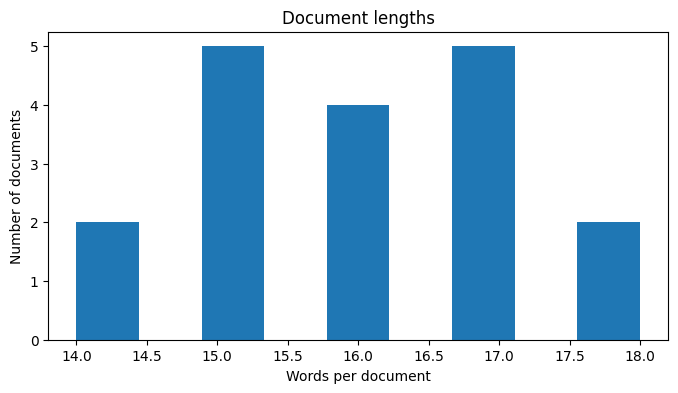

In [ ]:
df['word_count'] = df['text'].str.split().str.len()
display(df['word_count'].describe().to_frame('Words per document'))
plt.figure(figsize=(8,4)); plt.hist(df['word_count'], bins=min(25,max(5,len(df)//2)))
plt.xlabel('Words per document');plt.ylabel('Number of documents');plt.title('Document lengths');plt.show()

## 3. Clean the text with spaCy
We lowercase, lemmatize, and retain alphabetic content words. You can add corpus-specific stopwords (for example, names or boilerplate). These choices affect the topics: document and justify them in your research notes. The second function cleans the text to just nouns and descriptive words. Choose which cleaning option works best for your corpus

In [ ]:
CUSTOM_STOPWORDS = {'said', 'say', 'chapter'}  # edit for your corpus
KEEP_POS = {'NOUN','PROPN','ADJ','VERB'}  # use None to keep all non-stopword alphabetic tokens
MIN_TOKEN_LENGTH = 3

def preprocess_docs(texts, mode="standard"):
    output = []

    for doc in nlp.pipe(texts, batch_size=32):
        tokens = []

        for tok in doc:
            # Remove punctuation, spaces, numbers, and nonalphabetic tokens
            if tok.is_punct or tok.is_space or tok.like_num or not tok.is_alpha:
                continue

            # Remove stopwords
            if tok.is_stop:
                continue

            # Filter by part of speech
            if mode == "nouns":
                if tok.pos_ != "NOUN":
                    continue

            elif mode == "descriptive":
                if tok.pos_ not in ["NOUN", "PROPN", "ADJ", "VERB"]:
                    continue

            # Apply existing POS filter, if specified
            if KEEP_POS is not None and tok.pos_ not in KEEP_POS:
                continue

            # Lemmatize and lowercase
            lemma = tok.lemma_.lower().strip()

            if (len(lemma) >= MIN_TOKEN_LENGTH
                and lemma not in CUSTOM_STOPWORDS):
                tokens.append(lemma)

        output.append(tokens)

    return output

In [ ]:
CLEANING_MODE = "nouns"  # "standard", "nouns", or "descriptive"

token_lists = preprocess_docs(
    df["text"].fillna("").tolist(),
    mode=CLEANING_MODE
)

df["cleaned_text"] = [" ".join(tokens) for tokens in token_lists]

display(df[["title", "cleaned_text"]].head())

,title,cleaned_text
0,Education 1,student peer feedback classroom revision teach...
1,Education 2,university course assignment workshop thinking...
2,Education 3,platform teacher lesson student writing classr...
3,Education 4,student research skill source evidence teacher...
4,Education 5,instruction drafting revision audience awarene...


## 4. Build the document–term matrix
The document–term matrix counts words in each document. `min_df` removes extremely rare terms, while `max_df` removes terms found in almost every document. For a small corpus, less aggressive filtering is safer.

In [ ]:
MIN_DF = 2 if len(df)>=20 else 1
MAX_DF = 0.95 if len(df)>=20 else 1.0
MAX_FEATURES = 5000
vectorizer=CountVectorizer(min_df=MIN_DF,max_df=MAX_DF,max_features=MAX_FEATURES)
X=vectorizer.fit_transform(df['cleaned_text'])
if X.shape[1]<3: raise ValueError('Too few vocabulary terms; relax preprocessing or filtering.')
if (np.asarray(X.sum(axis=1)).ravel()==0).any():
    print('Warning: some documents have no retained terms; consider adjusting preprocessing.')
print('Document–term matrix:',X.shape)
print('Vocabulary sample:',vectorizer.get_feature_names_out()[:25])

Document–term matrix: (18, 110)
Vocabulary sample: ['activity' 'animal' 'anxiety' 'assessment' 'assignment' 'audience'
 'awareness' 'beach' 'biodiversity' 'carbon' 'care' 'change' 'citation'
 'city' 'classroom' 'climate' 'clinic' 'collaboration' 'communication'
 'community' 'conservation' 'counseling' 'course' 'decision' 'diet']


## 5. Compare candidate numbers of topics
We calculate **c_v coherence** (higher often indicates more semantically related top words) and **held-out perplexity** (lower indicates better prediction on held-out documents). Neither guarantees meaningful topics. Coherence is calculated using the preprocessed token lists and top words from each fitted LDA model. For small corpora, results can be unstable.

**Teaching note:** Coherence and perplexity answer different questions and may prefer different topic counts. We use coherence to propose a candidate, then inspect interpretability and topic overlap before making the final choice.

In [ ]:
# Edit these parameters for your corpus and available Colab runtime.
MIN_TOPICS = 2
MAX_TOPICS = min(12, max(2,len(df)//3))
TOPIC_STEP = 1
TOP_WORDS = 12
MAX_ITER = 30

from sklearn.model_selection import train_test_split
indices=np.arange(len(df))
if len(df)>=10:
    train_idx,test_idx=train_test_split(indices,test_size=0.2,random_state=RANDOM_STATE)
else:
    train_idx,test_idx=indices,indices
    print('Small corpus: perplexity is in-sample (not held-out). Interpret cautiously.')
X_train=X[train_idx]; X_test=X[test_idx]
coherence_texts=[token_lists[i] for i in train_idx]
dictionary=Dictionary(coherence_texts)
terms=vectorizer.get_feature_names_out()
results=[]
for k in range(MIN_TOPICS,MAX_TOPICS+1,TOPIC_STEP):
    model=LatentDirichletAllocation(n_components=k,random_state=RANDOM_STATE,
                                     max_iter=MAX_ITER,learning_method='batch')
    model.fit(X_train)
    top_terms=[[terms[j] for j in topic.argsort()[-TOP_WORDS:][::-1]] for topic in model.components_]
    coherence=CoherenceModel(topics=top_terms,texts=coherence_texts,
                             dictionary=dictionary,coherence='c_v',processes=1).get_coherence()
    perplexity=model.perplexity(X_test)
    results.append({'n_topics':k,'coherence_cv':coherence,'perplexity':perplexity})
    print(f'{k:2d} topics | coherence={coherence:.3f} | perplexity={perplexity:.1f}')
evaluation=pd.DataFrame(results)
display(evaluation)

 2 topics | coherence=0.324 | perplexity=2501.5
 3 topics | coherence=0.403 | perplexity=10196.2
 4 topics | coherence=0.433 | perplexity=23224.1
 5 topics | coherence=0.409 | perplexity=81655.4
 6 topics | coherence=0.424 | perplexity=247421.7


,n_topics,coherence_cv,perplexity
0,2,0.324174,2501.485497
1,3,0.402515,10196.217782
2,4,0.432814,23224.077107
3,5,0.408576,81655.405958
4,6,0.424489,247421.749174


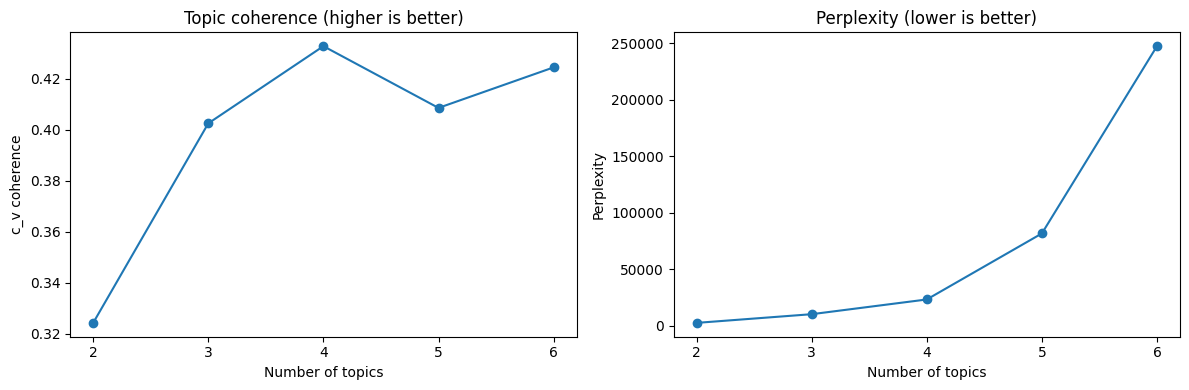

Highest-coherence candidate: 4
Inspect the topics before deciding. This is a suggestion, not an objectively optimal answer.


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(evaluation.n_topics,evaluation.coherence_cv,'o-')
axes[0].set(title='Topic coherence (higher is better)',xlabel='Number of topics',ylabel='c_v coherence')
axes[1].plot(evaluation.n_topics,evaluation.perplexity,'o-')
axes[1].set(title='Perplexity (lower is better)',xlabel='Number of topics',ylabel='Perplexity')
for ax in axes: ax.set_xticks(evaluation.n_topics)
plt.tight_layout();plt.show()
recommended_k=int(evaluation.loc[evaluation.coherence_cv.idxmax(),'n_topics'])
print('Highest-coherence candidate:',recommended_k)
print('Inspect the topics before deciding. This is a suggestion, not an objectively optimal answer.')

## 6. Choose the number of topics and fit the final model
Change `N_TOPICS` to a value you want to defend. The final model is fitted to **all documents** after exploratory selection. Because evaluation used a training subset, final topic words may differ slightly.

In [ ]:
N_TOPICS = recommended_k  # change to another tested value if more interpretable
lda=LatentDirichletAllocation(n_components=N_TOPICS,random_state=RANDOM_STATE,
                               max_iter=MAX_ITER,learning_method='batch')
lda.fit(X)
topic_probs=lda.transform(X)
feature_names=vectorizer.get_feature_names_out()

def topic_words(model,n=12):
    return [[feature_names[j] for j in comp.argsort()[-n:][::-1]] for comp in model.components_]
for i,words in enumerate(topic_words(lda,TOP_WORDS),1):
    print(f'Topic {i}: '+', '.join(words))

Topic 1: carbon, record, doctor, result, symptom, test, care, hospital, power, energy, emission, government
Topic 2: health, student, researcher, community, water, writing, activity, teacher, classroom, education, screening, prevention
Topic 3: treatment, heat, climate, planning, forest, wildlife, ecosystem, rainfall, conservation, patient, pattern, scientist
Topic 4: student, essay, peer, revision, feedback, classroom, teacher, drafting, awareness, audience, instruction, review


### Give the topics interpretive names
LDA assigns numbers, not meaningful labels. After reading the word lists and representative documents, edit the names below. You can rerun this cell and subsequent cells without retraining.

In [ ]:
TOPIC_LABELS = {i: f'Topic {i}' for i in range(1,N_TOPICS+1)}
# Example: TOPIC_LABELS[1] = 'Landscape and memory'
print(TOPIC_LABELS)

{1: 'Topic 1', 2: 'Topic 2', 3: 'Topic 3', 4: 'Topic 4'}


## 7. Interactive LDA visualization (pyLDAvis)
Each circle represents a topic; circle size approximates prevalence and distances summarize differences in term distributions. Select a circle to inspect characteristic words. Change the relevance slider to compare common and distinctive terms. The visualization is exploratory, not a proof of discrete themes.

In [ ]:
import pyLDAvis
import pyLDAvis.lda_model
pyLDAvis.enable_notebook()
vis=pyLDAvis.lda_model.prepare(lda,X,vectorizer,sort_topics=False)
pyLDAvis.display(vis)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8. Topic word clouds
Word size represents **relative word weight within a topic**, not necessarily the frequency of a word in the entire corpus. Select topics by changing `SELECTED_TOPICS`.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

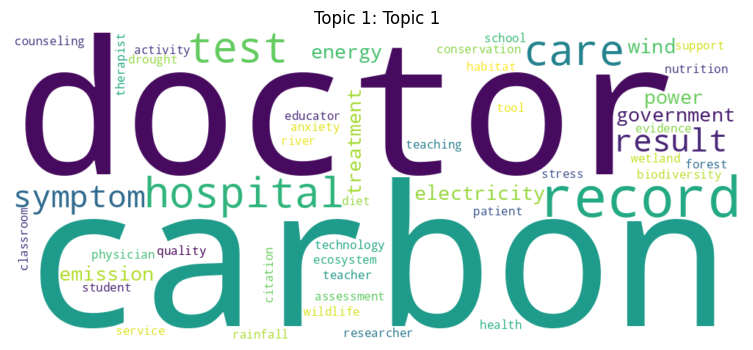

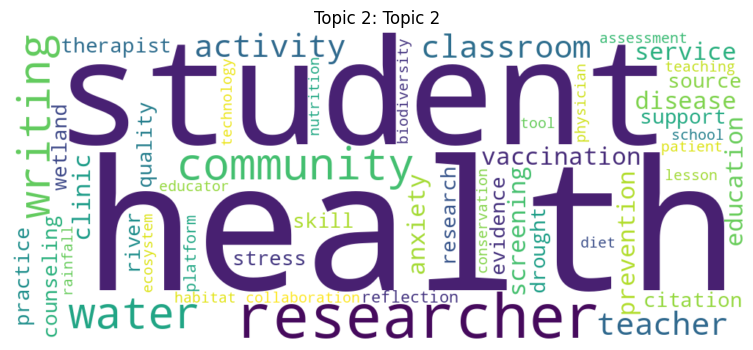

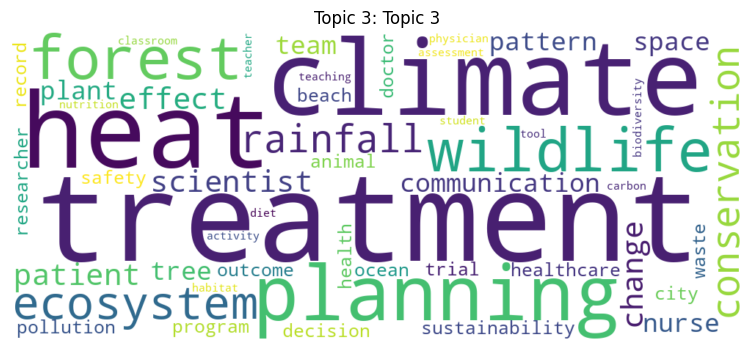

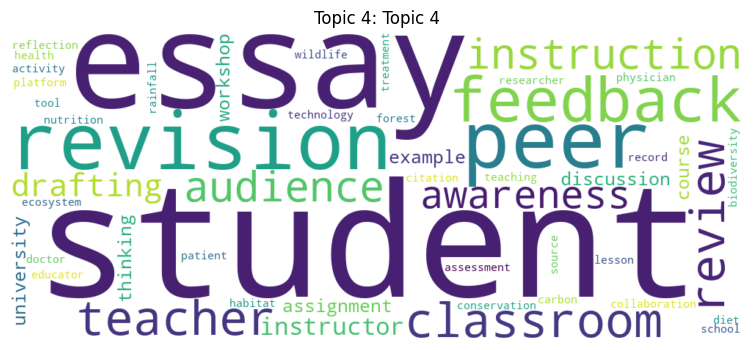

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*datetime\.datetime\.utcnow\(\).*"
)


SELECTED_TOPICS = list(range(1,min(N_TOPICS,6)+1)) # e.g., [1,3,5]
for t in SELECTED_TOPICS:
    if not 1<=t<=N_TOPICS: raise ValueError(f'Invalid topic: {t}')
    weights={feature_names[j]:float(lda.components_[t-1,j])
             for j in lda.components_[t-1].argsort()[-50:]}
    cloud=WordCloud(width=1000,height=420,background_color='white',random_state=RANDOM_STATE)
    cloud.generate_from_frequencies(weights)
    plt.figure(figsize=(11,4));plt.imshow(cloud,interpolation='bilinear');plt.axis('off')
    plt.title(f'Topic {t}: {TOPIC_LABELS[t]}');plt.show()

## 9. Bar charts: topic prevalence and top terms
Average topic probability shows how strongly each topic is represented **across documents**, weighting each document equally. This differs from total word frequency. The second chart displays the highest-weighted words in a selected topic.

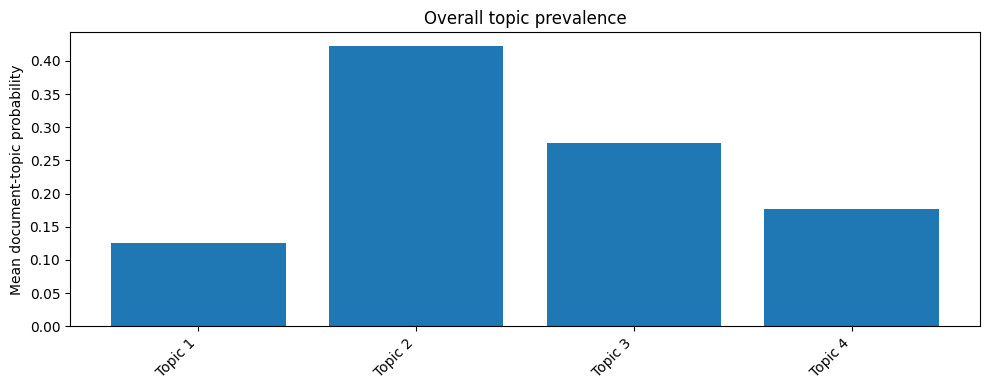

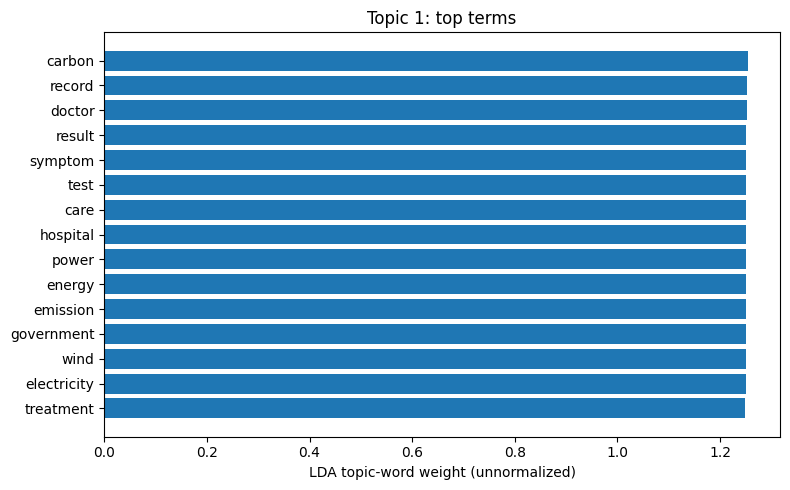

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*datetime\.datetime\.utcnow\(\).*"
)
mean_prevalence=topic_probs.mean(axis=0)
plt.figure(figsize=(10,4))
plt.bar([TOPIC_LABELS[i] for i in range(1,N_TOPICS+1)],mean_prevalence)
plt.xticks(rotation=45,ha='right');plt.ylabel('Mean document-topic probability')
plt.title('Overall topic prevalence');plt.tight_layout();plt.show()

BAR_CHART_TOPIC = 1  # change to explore a different topic
indices=lda.components_[BAR_CHART_TOPIC-1].argsort()[-15:][::-1]
plt.figure(figsize=(8,5))
plt.barh(feature_names[indices][::-1],lda.components_[BAR_CHART_TOPIC-1,indices][::-1])
plt.xlabel('LDA topic-word weight (unnormalized)');plt.title(f'Topic {BAR_CHART_TOPIC}: top terms')
plt.tight_layout();plt.show()

## 10. Document-topic probabilities and representative documents
A document can contain several topics. We define its **dominant topic** as the one with the highest estimated probability. The most representative documents for a topic are those with the highest probability for that topic; these are useful starting points for close reading, not automatic proof of membership.

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*datetime\.datetime\.utcnow\(\).*"
)

topic_columns=[f'Topic {i}' for i in range(1,N_TOPICS+1)]
prob_df=pd.DataFrame(topic_probs,columns=topic_columns)
document_topics=pd.concat([df.reset_index(drop=True),prob_df],axis=1)
document_topics['dominant_topic']=topic_probs.argmax(axis=1)+1
document_topics['dominant_topic_label']=document_topics['dominant_topic'].map(TOPIC_LABELS)
document_topics['dominant_topic_probability']=topic_probs.max(axis=1)
display(document_topics[['document_id','title','dominant_topic_label','dominant_topic_probability']+topic_columns].head(10))

,document_id,title,dominant_topic_label,dominant_topic_probability,Topic 1,Topic 2,Topic 3,Topic 4
0,1,Education 1,Topic 4,0.915887,0.027805,0.028513,0.027794,0.915887
1,2,Education 2,Topic 4,0.924846,0.025028,0.025109,0.025017,0.924846
2,3,Education 3,Topic 2,0.924280,0.025041,0.924280,0.025025,0.025653
3,4,Education 4,Topic 2,0.924417,0.025049,0.924417,0.025030,0.025504
4,5,Education 5,Topic 4,0.924850,0.025026,0.025108,0.025016,0.924850
5,6,Education 6,Topic 2,0.915934,0.027836,0.915934,0.027813,0.028418
6,7,Environment 1,Topic 3,0.924520,0.025040,0.025409,0.924520,0.025032
7,8,Environment 2,Topic 3,0.916228,0.027829,0.028126,0.916228,0.027818
8,9,Environment 3,Topic 1,0.906064,0.906064,0.031387,0.031271,0.031278
9,10,Environment 4,Topic 2,0.904025,0.031977,0.904025,0.032694,0.031304


In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*datetime\.datetime\.utcnow\(\).*"
)
TOP_N_DOCS = 5
representative=[]
for i,col in enumerate(topic_columns,1):
    subset=document_topics.nlargest(TOP_N_DOCS,col).copy()
    subset['selected_topic']=i
    subset['selected_topic_label']=TOPIC_LABELS[i]
    subset['selected_topic_probability']=subset[col]
    subset['rank_within_topic']=range(1,len(subset)+1)
    representative.append(subset)
representative_docs=pd.concat(representative,ignore_index=True)
display(representative_docs[['selected_topic_label','rank_within_topic','title','selected_topic_probability','word_count']])

,selected_topic_label,rank_within_topic,title,selected_topic_probability,word_count
0,Topic 1,1,Health 1,0.915826,17
1,Topic 1,2,Environment 3,0.906064,16
2,Topic 1,3,Health 3,0.041742,14
3,Topic 1,4,Environment 4,0.031977,14
4,Topic 1,5,Health 4,0.028023,16
5,Topic 2,1,Health 2,0.931576,15
6,Topic 2,2,Health 5,0.924600,15
7,Topic 2,3,Education 4,0.924417,17
8,Topic 2,4,Education 3,0.924280,17
9,Topic 2,5,Environment 5,0.924272,15


### Read excerpts from representative documents
Inspect the original language behind the statistical results. Consider whether the words indicate a coherent rhetorical, literary, or historical pattern.

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*datetime\.datetime\.utcnow\(\).*"
)
INSPECT_TOPIC = 1
EXCERPT_CHARACTERS = 500
subset=representative_docs[representative_docs.selected_topic==INSPECT_TOPIC]
for _,row in subset.iterrows():
    print(f"\n{row['title']} | topic probability: {row['selected_topic_probability']:.3f}")
    print(row['text'][:EXCERPT_CHARACTERS].replace('\n',' ')+'...')


Health 1 | topic probability: 0.916
Hospitals use patient records to coordinate treatment and medical care. Doctors review symptoms and clinical test results....

Environment 3 | topic probability: 0.906
Renewable energy from wind and solar power can reduce carbon emissions. Governments invest in cleaner electricity....

Health 3 | topic probability: 0.042
Nutrition and exercise support cardiovascular health. Physicians recommend healthy diets and regular physical activity....

Environment 4 | topic probability: 0.032
Forests absorb carbon and provide habitats for wildlife. Deforestation threatens biodiversity and ecosystem health....

Health 4 | topic probability: 0.028
Medical researchers evaluate new treatments through clinical trials. Patient safety and treatment outcomes guide healthcare decisions....


## 11. Compare topic prevalence by title
If your CSV contains multiple passages per work, averaging probabilities by `title` lets you compare works. If each title appears only once, the chart compares individual documents. For many titles, display the top `MAX_TITLES_TO_PLOT` by document count.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

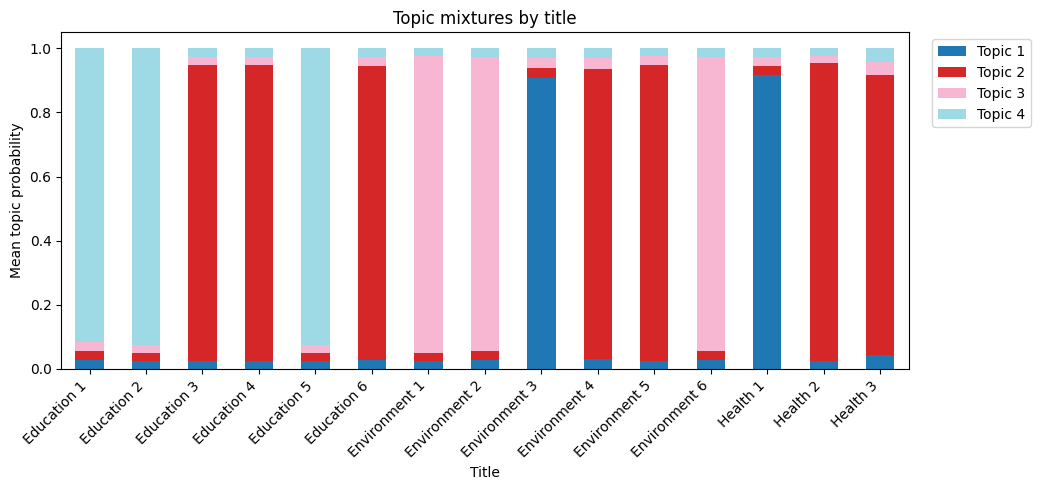

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
MAX_TITLES_TO_PLOT = 15
popular_titles=document_topics['title'].value_counts().head(MAX_TITLES_TO_PLOT).index
by_title=document_topics[document_topics.title.isin(popular_titles)].groupby('title')[topic_columns].mean()
ax=by_title.plot(kind='bar',stacked=True,figsize=(max(10,len(by_title)*0.7),5),colormap='tab20')
ax.set_ylabel('Mean topic probability');ax.set_xlabel('Title');ax.set_title('Topic mixtures by title')
plt.xticks(rotation=45,ha='right');plt.legend(bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout();plt.show()

## 12. Export your results
We will create **four CSV files and one Excel workbook**: topic keywords/weights, all document-topic probabilities, top representative documents per topic, and evaluation scores. The workbook contains separate sheets for these tables. The document table includes the original texts and any additional metadata columns.

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*datetime\.datetime\.utcnow\(\).*"
)
topic_rows=[]
for i,component in enumerate(lda.components_,1):
    normalized=component/component.sum()
    for rank,j in enumerate(component.argsort()[-TOP_WORDS:][::-1],1):
        topic_rows.append({'topic_number':i,'topic_label':TOPIC_LABELS[i],
                           'word_rank':rank,'word':feature_names[j],
                           'topic_word_probability':float(normalized[j])})
topic_keywords=pd.DataFrame(topic_rows)

exports={
 'topic_keywords.csv':topic_keywords,
 'document_topic_probabilities.csv':document_topics,
 'representative_documents.csv':representative_docs,
 'topic_count_evaluation.csv':evaluation,
}
for filename,table in exports.items():
    table.to_csv(filename,index=False,encoding='utf-8-sig')
with pd.ExcelWriter('lda_topic_results.xlsx',engine='openpyxl') as writer:
    for sheet,table in [('Topic Keywords',topic_keywords),('Document Topics',document_topics),
                        ('Representative Docs',representative_docs),('Evaluation',evaluation)]:
        table.to_excel(writer,sheet_name=sheet,index=False)
print('Created:',list(exports)+['lda_topic_results.xlsx'])
from google.colab import files
files.download('lda_topic_results.xlsx')
# To download an individual CSV, uncomment one line below:
# files.download('representative_documents.csv')
# files.download('document_topic_probabilities.csv')

Created: ['topic_keywords.csv', 'document_topic_probabilities.csv', 'representative_documents.csv', 'topic_count_evaluation.csv', 'lda_topic_results.xlsx']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Interpretation and reflection

1. Which number of topics had the highest coherence? Did perplexity suggest the same number?
2. Compare two neighboring topic counts. Which produces more interpretable, less redundant topics?
3. Choose one topic: what do its top words suggest? Do the representative documents support that interpretation?
4. Are some topics dominated by a particular author, title, genre, or document length?
5. How might changing stopwords, lemmatization, or document segmentation change the results?
6. What can close reading reveal that the model cannot?

**Methods reporting checklist:** record corpus size and source, unit of analysis, cleaning choices, vectorizer settings, candidate topic range, evaluation method, chosen topic count, random seed, and interpretive labeling process.

### References and additional resources
- [scikit-learn: Latent Dirichlet Allocation](https://scikit-learn.org/stable/modules/decomposition.html#latentdirichletallocation)
- [pyLDAvis documentation](https://pyldavis.readthedocs.io/)
- [Gensim topic coherence](https://radimrehurek.com/gensim/models/coherencemodel.html)
- Blei, Ng, & Jordan (2003), *Latent Dirichlet Allocation*.
- Sievert & Shirley (2014), *LDAvis: A Method for Visualizing and Interpreting Topics*.